<img src="logo_UNSAM.jpg" align="right" width="150">

#### Análisis y Procesamiento de Señales

# *TS4 - Primeras nociones de estimación espectral*

### *Autora: Catalina Gonzalez Araujo*

### *Docentes: Mariano Llamedo Soria, David Ezequiel Benoit, Francisco Hernan Ledesma.*

# <u>**Resumen**</u>

En el presente trabajo se buscó analizar el comportamiento de una señal con ruido y su correspondiente procesamiento. Para ello, se sintetizaron 200 realizaciones de una señal sinusoidal con ruido aleatorio en su frecuencia y amplitud (con una distribución uniforme y normal, respectivamente). Se comprobaron 2 SNR distintos, uno igual a 3 dB y otro a 10 dB.

Posteriormente, se realizó el ventaneo de la señal, multiplicándola por distintas ventanas (Rectangular, Blackman, Hamming y Flat-top). 

Finalmente, se calculó la FFT de la señal con ruido ventaneada y se estimó la frecuencia y la energía de la señal. Para su respectivo análisis, se calculó el sesgo y la varianza de estos estimadores.

Los resultados se encuentran dentro del rango esperado y su análisis se observa en la conclusión.

# <u>**Introducción teórica**</u>

## 1. <u>**Señales y modelos estocásticos en procesamiento digital de señales**</u>
   
   En el análisis de señales digitales, es común modelar una señal como la combinación de una componente determinística y ruido aleatorio. La señal que se estudia en este trabajo está definida como: $x(n) = a_0 * \sin(\Omega_1 * n) + n_a(n)$

   Donde:
   
-	$a_0 = \sqrt{2}$ es la amplitud de la señal sinusoidal.

-	$\Omega_1 = \Omega_0 + f_r * \frac{2 * \pi}{N}$ es la frecuencia angular de la señal, ligeramente desintonizada respecto a $\Omega_0 = \frac{N}{2}$ (siendo $N$ el número de muestras).

-	$f_r ≈ U(-2, 2)$ representa un desplazamiento aleatorio uniforme de frecuencia, modelando pequeñas fluctuaciones o incertidumbre en la frecuencia de la señal.

-	$n_a(n) ≈ N(0, \sigma^2)$ es ruido blanco gaussiano aditivo (*AWGN*) con media cero y varianza $\sigma^2$, que representa perturbaciones aleatorias típicas en sistemas físicos.


Este modelo se conoce como modelo aditivo de señal con ruido, y es la base para muchos estudios de estimación en procesamiento digital de señales.

## 2. <u>**Señal vs Ruido y SNR**</u>
   
   El **SNR (Signal-to-Noise Ratio)** es la relación entre la potencia de la señal y la potencia del ruido: $SNR(dB) = 10 * \log_{10}{\frac{P_{señal}}{P_{ruido}}}$
   
-	Un *SNR* alto indica que la señal es mucho más fuerte que el ruido, facilitando su detección y estimación. 

-	Un *SNR* bajo indica que el ruido domina, haciendo más difícil estimar correctamente la amplitud y frecuencia de la señal.

## 3. <u>**Distribuciones de probabilidad**</u>
   
   Las distribuciones de probabilidad describen el comportamiento de variables aleatorias:
   
-	Distribución uniforme $U(a,b)$: todos los valores en el intervalo $[a,b]$ tienen la misma probabilidad.

-	Distribución normal $N(\mu, \sigma^2)$: la variable aleatoria tiene mayor probabilidad cerca de la media $\mu$ y menor probabilidad cuanto más se aleja de $\mu$. 

## 4. <u>**Estimación espectral**</u>

El **análisis espectral** es fundamental para el procesamiento digital de señales, ya que permite medir, estimar y caracterizar cómo se distribuye la energía o la potencia de una señal en el dominio de la frecuencia. Puede aplicarse tanto a señales determinísticas como probabilísticas. 

En general, los problemas del análisis espectral empiezan con funciones en el dominio continuo, las cuales son muestreadas por otra señal, con el objetivo de producir una señal digital $x[n]$. 

La caracterización de señales en el dominio de la frecuencia resulta sencilla:

-	Una señal sinusoidal infinita tiene todo su espectro concentrado en dos frecuencias, $w_0$ y $-w_0$.

-	La *Transformada Discreta de Fourier en el tiempo discreto* (*DTFT*) permite un análisis con resolución infinita en frecuencias.

Sin embargo, estas condiciones no se cumplen en la práctica. No es posible analizar señales de duración infinita, por lo que se trabaja con segmentos temporales finitos. Esto introduce efectos de ventaneo, que modifican el espectro observado. Además, al muestrear una señal continua, se debe elegir una frecuencia de muestreo adecuada para evitar aliasing. 

Por estas razones, en aplicaciones reales se utilizan versiones discretas y computacionales de la transformada, como la DFT y su implementación eficiente, la FFT, que permiten obtener estimaciones espectrales a partir de señales digitales de duración finita.

## 5. <u> **Ventaneo** </u>

En el procesamiento digital de señales, el análisis espectral mediante la Transformada Discreta de Fourier (*DFT*) supone implícitamente que la señal analizada es periódica dentro del intervalo de observación. Cuando la frecuencia de la señal no coincide exactamente con un múltiplo entero de la resolución espectral de la *DFT*, aparecen discontinuidades en los extremos del bloque analizado. Este fenómeno produce una dispersión de energía en el espectro conocida como **spectral leakage** o **fuga espectral**. 

Para reducir este efecto, se emplean funciones ventana $w(n)$, las cuales multiplican a la señal antes de calcular la *DFT*: 
$$
x_{w}(n)=x(n) \cdot w(n)
$$

El objetivo del ventaneo es suavizar los extremos de la señal temporal, disminuyendo las discontinuidades y reduciendo así la fuga espectral. Sin embargo, el uso de ventanas introduce un compromiso entre diferentes propiedades espectrales, principalmente: 

- **Ancho del lóbulo principal**: determina la *resolución espectral* en frecuencia.
- **Nivel de los lóbulos secundarios**: determina cuánto *leakage* aparece.
- **Precisión en amplitud**: algunas ventanas preservan mejor la amplitud de la señal que otras.

En este trabajo se analizarán distintas ventanas disponibles en *scipy.signal.windows*, evaluando su efecto sobre los estimadores de amplitud y frecuencia. 

### *Ventana Rectangular*

La ventana rectangular equivale a no aplicar ventaneo; es una ventana implícita.

$$
w(n)=1
$$

Presenta el lóbulo principal más angosto, lo que proporciona buena resolución espectral. Sin embargo, posee lóbulos secundarios elevados, generando una importante fuga espectral cuando la frecuencia de la señal no coincide exactamente con un bin de la *DFT*. 

### *Ventana Flat-top*

La ventana Flat-top está diseñada para mejorar la estimación de amplitud de componentes senoidales. Posee un lóbulo principal ancho y lóbulos secundarios muy atenuados. Esto reduce el error en amplitud, aunque empeora la resolución en frecuencia. 

### *Ventana Blackman-Harris*

La ventana Blackman-Harris reduce considerablemente los lóbulos secundarios, minimizando el leakage espectral. Como contrapartida, el lóbulo principal es más ancho que la ventana rectangular, disminuyendo la capacidad de distinguir frecuencias cercanas. 

### *Ventana de Hamming*

La ventana de Hamming es una de las más utilizadas en procesamiento digital de señales debido a su buen compromiso entre resolucion espectral y reducción del leakage. 

A diferencia de la ventana Rectangular, la ventana de Hamming atenúa los extremos de la señal, reduciendo significativamente los lóbulos secundarios del espectro, y por lo tanto, disminuyendo la fuga espectral. Esto permite obtener estimaciones espectrales más suaves y menos afectadas por componentes no deseados. 

Sin embargo, esta mejora implica un ensanchamiento del lóbulo principal respecto a la ventana rectangular, produciendo una ligera pérdida de resolución en frecuencia. Aun asi, la ventana de Hamming ofrece un equilibrio adecuado entre resolución y atenuación de leakage.

### *Trade - off entre resolución y leakage*

No existe una ventana óptima para todos los casos. Ventanas con lóbulos secundarios bajos reducen el leakage pero empeoran la resolución espectral. En cambio, ventanas con lóbulos principales angostos mejoran la resolución pero son más sensibles al leakage. Por esta razón, en este trabajo se comparará experimentalmente el desempeño de diferentes ventanas sobre los estimadores de amplitud y frecuencia. 

## 6. <u>**Estimadores de amplitud y frecuencia**</u>

   Un **estimador** es una regla o fórmula que permite calcular un valor aproximado de un parámetro desconocido de una señal a partir de datos observados.
   
Para estimar la amplitud $a_1$ y la frecuencia $\omega_1$ de la señal, se usan los siguientes estimadores basados en la *DFT* de la señal ventana $w_i(n)$: 

-	**Estimador de amplitud**: intenta determinar el valor real de la amplitud de la señal sinusoidal a partir de sus muestras.

$$
a^{1}_{i} = \left| X^{w}_{i}(\Omega_{0}) \right| = \left| \mathrm{DFT} \left\{ x(n) \cdot w_{i}(n) \right\} \right|_{\Omega_{0}}
$$

-   **Estimador de frecuencia**: busca aproximar la frecuencia real de la señal.

$$
\Omega^{1}_{i} = \arg\max_{\Omega} \left| X^{w}_{i}(\Omega) \right|
$$

Es decir, la amplitud se obtiene evaluando el módulo de la DFT en la frecuencia nominal $\Omega_0$, mientras que la frecuencia se estima buscando el máximo del espectro de la señal ventana.

## 7. <u>**Sesgo y varianza de estimadores**</u>

   Un estimador se evalúa en términos de **sesgo** y **varianza**, que reflejan su precisión y consistencia.
    
-	Sesgo ($s_a$): es la diferencia entre la media esperada del estimador y el valor real: 
$$
s_a = E\{\hat{a}_0\} - a_0
$$

-	Varianza ($v_a$): medida de la dispersión de los resultados alrededor de la media:
$$
v_a = \text{var}\{\hat{a}_0\} = E\left\{(\hat{a}_0 - E\{\hat{a}_0\})^2\right\}
$$

	Cuando se trabaja con simulaciones o experimentos numéricos, los valores esperados se aproximan mediante promedios muestrales sobre $M$ realizaciones: 

$$
E\{\hat{a}_0\} = \hat{\mu}_a = \frac{1}{M} \sum_{j=0}^{M-1} \hat{a}_j, \quad s_a = \hat{\mu}_a - a_0, \quad v_a = \frac{1}{M} \sum_{j=0}^{M-1} (\hat{a}_j - \hat{\mu}_a)^2
$$

   De manera análoga, se puede calcular el sesgo y la varianza del estimador de frecuencias $\Omega_1$.

# <u>**Desarrollo**</u>

A continuación, se detallan los procedimientos realizados para cumplir con las consignas propuestas. 

En primer lugar, se importaron las librerías necesarias y se definieron los parámetros comunes utilizados en todos los análisis realizados.

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import windows

# Estas dos librerias son para hacer la tabla del sesgo y la varianza
from IPython.display import HTML 
import pandas as pd

# Parámetros
N = 1000 # cantidad de muestras
R = 200 # cantidad de realizaciones
fs = 1000 # frecuencia de muestreo
df = fs / N
Ts = 1 / fs
a0 = np.sqrt(2) # amplitud
omega0 = N/4
fr = np.random.uniform(-2,2, size = R)

# Eje de muestras
n = np.arange(N)
n = n.reshape(1, N)

t = np.arange(N) / fs
tt = np.tile(t, (R,1))   # matriz 200x1000

omega1 = omega0 + fr * df
omega1 = omega1.reshape(R, 1)

ff = np.arange(N) # Vector en frecuencia al escalar las muestras por la resolucion espectral
f = omega1*n
ff = ff.reshape(1000, 1)

Luego, se estableció una relación señal - ruido de $SNR = 10dB$, a partir del cual se definió el ruido $na$. Posteriormente, se generó la señal senoidal

$$señal = a_{0} \cdot sin(2 \cdot \pi \cdot f \cdot T_{s})+n_{a}$$

y se realizó su representación en el dominio temporal.

A continuación, se calculó la *FFT* de la señal y se graficó su espectro en $dB$.

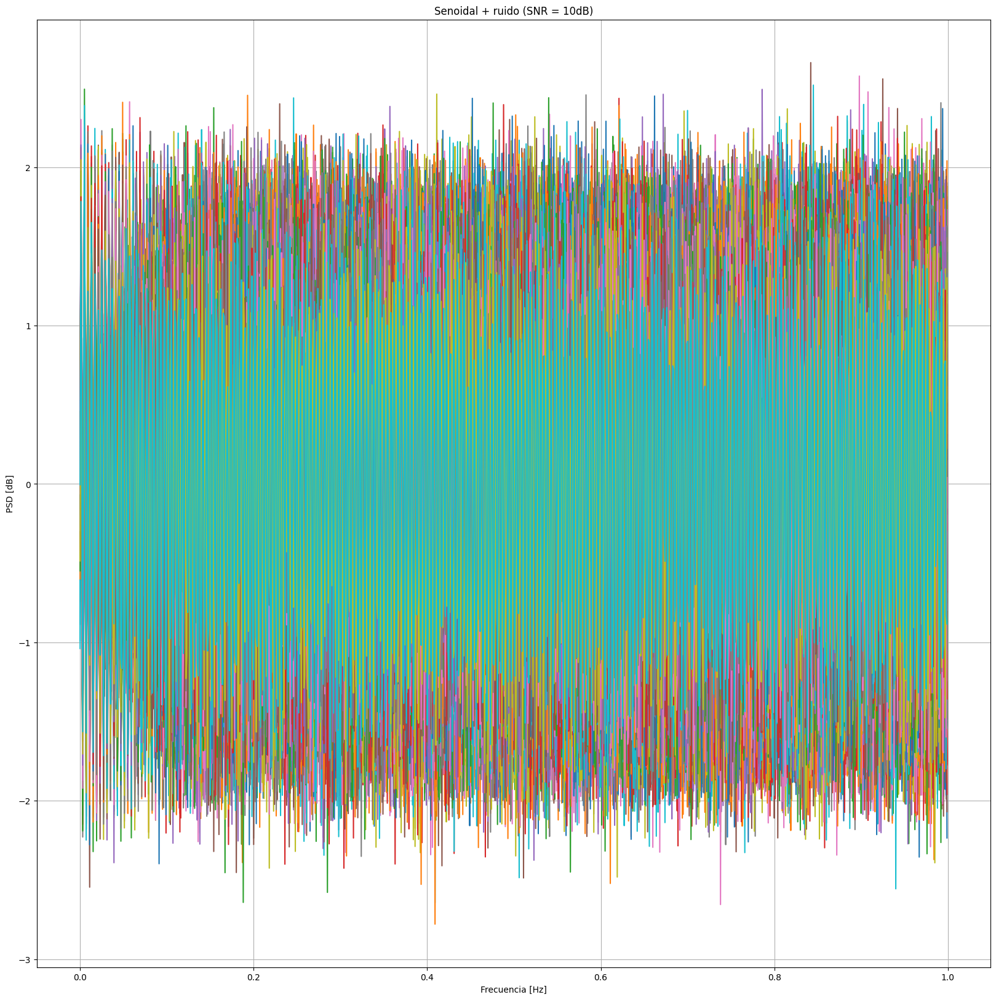

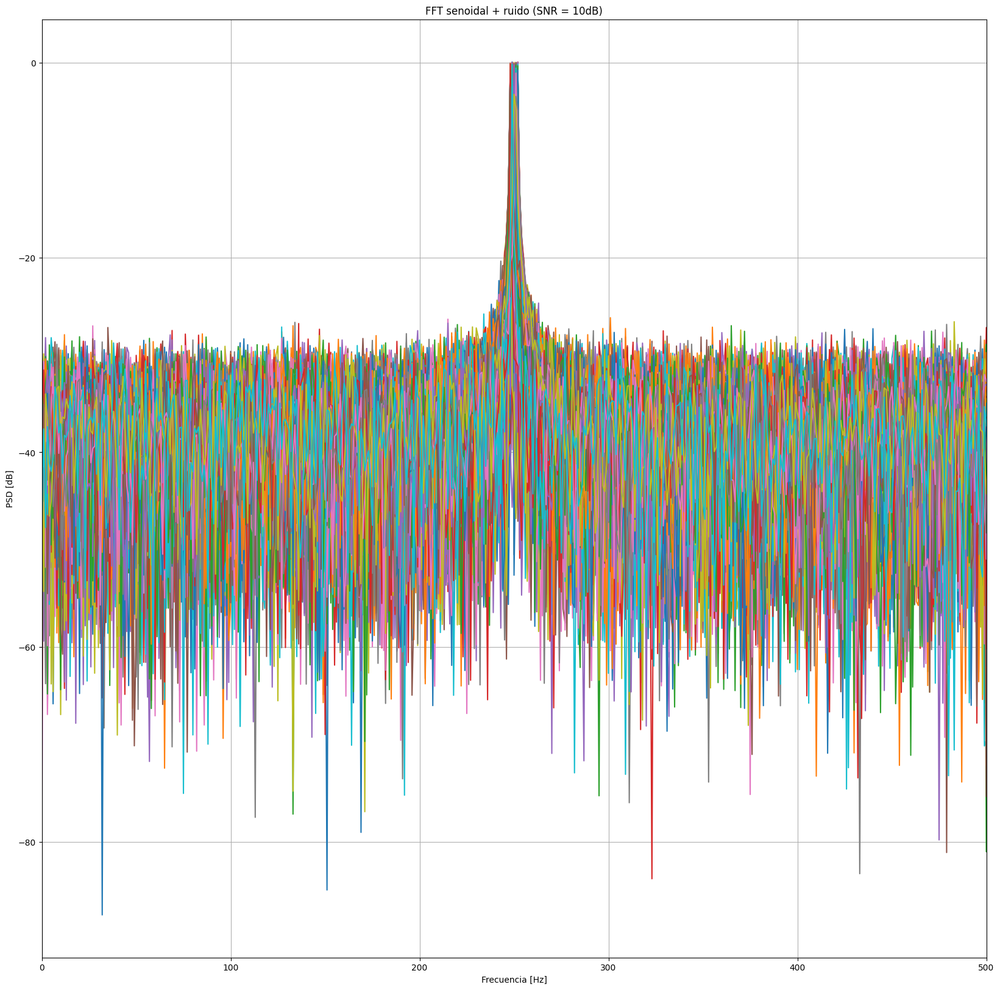

In [24]:
#%% SNR = 10dB
SNR = 10 # en dB
Ps = a0**2 / 2
Pr = Ps / (10**(SNR/10))
desvio = np.sqrt(Pr)

na = np.random.normal(0, desvio, size = (R, N)) # ruido

# Señal
s_mat_10 = a0 * np.sin(2 * np.pi * f * Ts) + na

# Traspongo la señal para poder graficarla 
señal_t10 = np.transpose(s_mat_10)

plt.figure(figsize = (20, 20))
plt.title("Senoidal + ruido (SNR = 10dB)")
plt.plot(t, señal_t10)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB]') # Es la densidad espectral de potencia 
plt.grid()
plt.show()

# FFT
eps = 1e-12
S_mat_10 = np.fft.fft(s_mat_10, axis = 1) / N
S_mat_modulo10 = np.abs(S_mat_10)
S_mat_dB10 = 10 * np.log10(2*(S_mat_modulo10)**2 + eps)
S_mat_dB10 = np.transpose(S_mat_dB10)

plt.figure(figsize = (20, 20))
plt.title("FFT senoidal + ruido (SNR = 10dB)")
plt.plot(ff, S_mat_dB10)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB]') # Es la densidad espectral de potencia 
plt.xlim(0, fs/2)
plt.grid()
plt.show()

Posteriormente, se aplicaron distintas ventanas a la señal con el objetivo de analizar el comportamiento de cada una de ellas.  

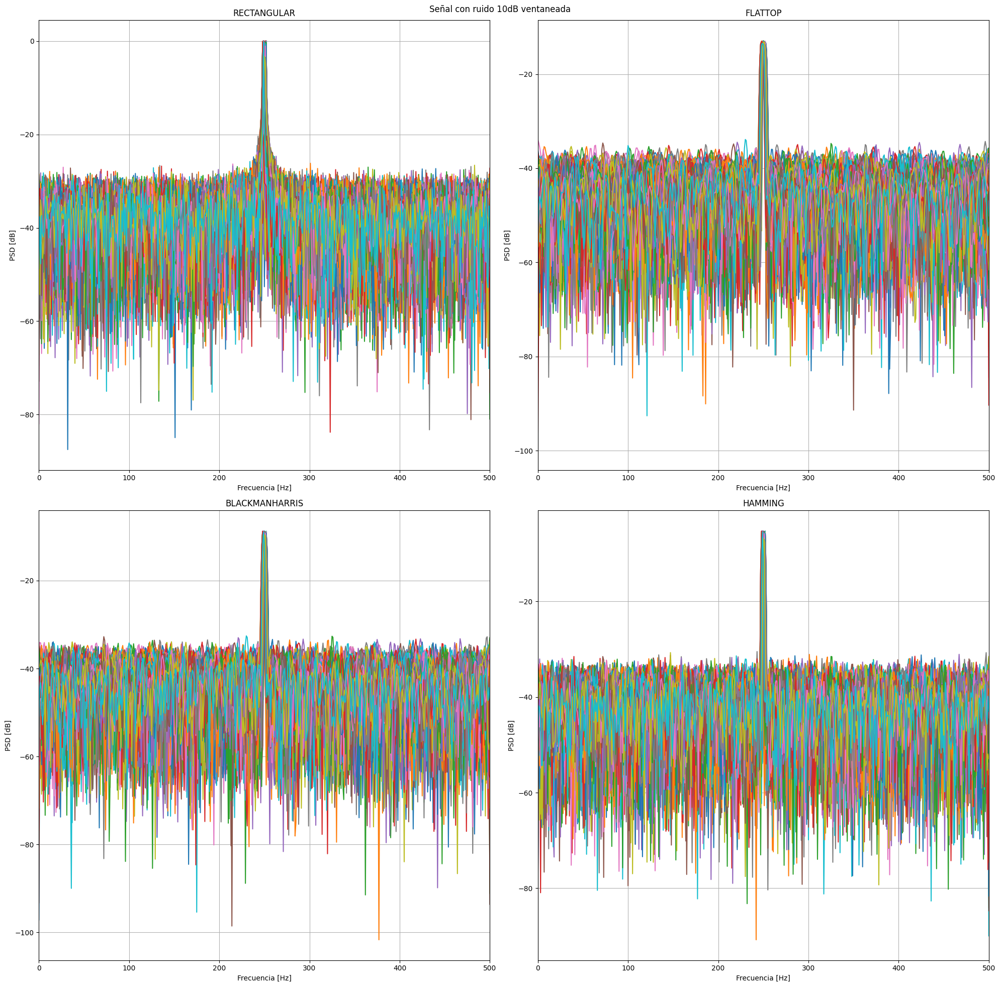

In [25]:
#%% Ventaneo SNR = 10dB 
# RECTANGULAR
s_vent_R10 = s_mat_10 * windows.boxcar(N)

S_vent_R10 = np.fft.fft(s_vent_R10, axis=1) / N
S_vent_modulo_R10 = np.abs(S_vent_R10)
S_vent_R10_dB = 10 * np.log10(2*(S_vent_modulo_R10)**2 + eps)
S_vent_R10_dB = np.transpose(S_vent_R10_dB)

# FLATTOP
s_vent_F10 = s_mat_10 * windows.flattop(N)

S_vent_F10 = np.fft.fft(s_vent_F10, axis=1) / N
S_vent_modulo_F10 = np.abs(S_vent_F10)
S_vent_F10_dB = 10 * np.log10(2*(S_vent_modulo_F10)**2 + eps)
S_vent_F10_dB = np.transpose(S_vent_F10_dB)

# BLACKMANHARRIS
s_vent_B10 = s_mat_10 * windows.blackmanharris(N)

S_vent_B10 = np.fft.fft(s_vent_B10, axis=1) / N
S_vent_modulo_B10 = np.abs(S_vent_B10)
S_vent_B10_dB = 10 * np.log10(2*(S_vent_modulo_B10)**2 + eps)
S_vent_B10_dB = np.transpose(S_vent_B10_dB)

# HAMMING
s_vent_H10 = s_mat_10 * windows.hamming(N)

S_vent_H10 = np.fft.fft(s_vent_H10, axis=1) / N
S_vent_modulo_H10 = np.abs(S_vent_H10)
S_vent_H10_dB = 10 * np.log10(2*(S_vent_modulo_H10)**2 + eps)
S_vent_H10_dB = np.transpose(S_vent_H10_dB)

# Graficos
plt.figure(figsize = (20, 20))
plt.suptitle("Señal con ruido 10dB ventaneada")

plt.subplot(2,2,1)
plt.title("RECTANGULAR")
plt.plot(ff, S_vent_R10_dB)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB]') # Es la densidad espectral de potencia 
plt.xlim(0, fs/2)
plt.grid()

plt.subplot(2,2,2)
plt.title("FLATTOP")
plt.plot(ff, S_vent_F10_dB)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB]') # Es la densidad espectral de potencia 
plt.xlim(0, fs/2)
plt.grid()

plt.subplot(2,2,3)
plt.title("BLACKMANHARRIS")
plt.plot(ff, S_vent_B10_dB)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB]') # Es la densidad espectral de potencia 
plt.xlim(0, fs/2)
plt.grid()

plt.subplot(2,2,4)
plt.title("HAMMING")
plt.plot(ff, S_vent_H10_dB)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB]') # Es la densidad espectral de potencia 
plt.xlim(0, fs/2)
plt.grid()

plt.tight_layout()
plt.show()

Finalmente, se implementaron estimadores de amplitud (energía) y de frecuencia. Luego, se calculó el sesgo y la varianza asociados a cada estimador. 

In [26]:
#%% Estimador de amplitud SNR = 10dB
# SNR = 10dB
estimador_a_R10 = np.abs(S_vent_R10[:, N//4])*2
estimador_a_F10 = np.abs(S_vent_F10[:, N//4])*2
estimador_a_B10 = np.abs(S_vent_B10[:, N//4])*2
estimador_a_H10 = np.abs(S_vent_H10[:, N//4])*2

#%% SESGO Y VARIANZA SNR = 10dB
sesgo_amp_R10 = np.mean(estimador_a_R10) - a0 
sesgo_amp_F10 = np.mean(estimador_a_F10) - a0 
sesgo_amp_B10 = np.mean(estimador_a_B10) - a0 
sesgo_amp_H10 = np.mean(estimador_a_H10) - a0 

varianza_amp_R10 = np.var(estimador_a_R10)
varianza_amp_F10 = np.var(estimador_a_F10)
varianza_amp_B10 = np.var(estimador_a_B10)
varianza_amp_H10 = np.var(estimador_a_H10)

# Tabla de estimación de amplitud
tabla_amp = pd.DataFrame({
    "sesgo": [sesgo_amp_R10, sesgo_amp_F10, sesgo_amp_B10, sesgo_amp_H10],
    "varianza": [varianza_amp_R10, varianza_amp_F10, varianza_amp_B10, varianza_amp_H10]
}, index=["Rectangular", "Flat-top", "Blackman", "Hann"])

titulo = "Estimaión de amplitud (SNR = 10dB)"
print(titulo.center(150))

# Mostrar centradas con HTML
html_amp = tabla_amp.to_html(float_format="%.3f")

display(HTML(f"<div style='display: flex; justify-content: center'>{html_amp}</div>"))


#%% Estimador de la frecuencia SNR = 10dB
estimador_f_R10 = np.argmax(np.abs(S_vent_R10[:, :N//2]), axis = 1)
estimador_f_F10 = np.argmax(np.abs(S_vent_F10[:, :N//2]), axis = 1)
estimador_f_B10 = np.argmax(np.abs(S_vent_B10[:, :N//2]), axis = 1)
estimador_f_H10 = np.argmax(np.abs(S_vent_H10[:, :N//2]), axis = 1)

#%% SESGO Y VARIANZA SNR = 10dB
sesgo_frec_R10 = np.mean(estimador_f_R10) - np.mean(omega1)
sesgo_frec_F10 = np.mean(estimador_f_F10) - np.mean(omega1)
sesgo_frec_B10 = np.mean(estimador_f_B10) - np.mean(omega1)
sesgo_frec_H10 = np.mean(estimador_f_H10) - np.mean(omega1)

varianza_frec_R10 = np.var(estimador_f_R10)
varianza_frec_F10 = np.var(estimador_f_F10)
varianza_frec_B10 = np.var(estimador_f_B10)
varianza_frec_H10 = np.var(estimador_f_H10)

# Tabla de estimación de frecuencia
tabla_frec = pd.DataFrame({
    "sesgo": [sesgo_frec_R10, sesgo_frec_F10, sesgo_frec_B10, sesgo_frec_H10],
    "varianza": [varianza_frec_R10, varianza_frec_F10, varianza_frec_B10, varianza_frec_H10]
}, index=["Rectangular", "Flat-top", "Blackman", "Hann"])

titulo = "Estimaión de frecuencia (SNR = 10dB)"
print(titulo.center(145))

# Mostrar centradas con HTML
html_frec = tabla_frec.to_html(float_format="%.3f")

display(HTML(f"<div style='display: flex; justify-content: center'>{html_frec}</div>"))

                                                          Estimaión de amplitud (SNR = 10dB)                                                          


,sesgo,varianza
Rectangular,-0.923,0.216
Flat-top,-1.138,0.001
Blackman,-1.093,0.018
Hann,-1.078,0.073


                                                       Estimaión de frecuencia (SNR = 10dB)                                                      


,sesgo,varianza
Rectangular,-0.008,1.630
Flat-top,-0.078,1.571
Blackman,-0.013,1.614
Hann,-0.008,1.630


Posteriormente, se realizó el ejercicio *bonus*, en el cual se analizó el efecto del *zero padding* sobre el estimador de frecuencia.

In [27]:
#%% Efecto del zero padding en el estimador de frecuencia (SNR = 10dB)
N_zp = 2 * N  # 2000 puntos

# Rectangular
zp_W_R10 = np.fft.fft(s_vent_R10, n = N_zp, axis = 1)
estimador_f_zp_R10 = np.argmax(np.abs(zp_W_R10[:, :N_zp//2]), axis = 1) / 2
# Dividir por 2 porque los bins ahora son la mitad de anchos

# Flattop
zp_W_F10 = np.fft.fft(s_vent_F10, n = N_zp, axis  =1)
estimador_f_zp_F10 = np.argmax(np.abs(zp_W_F10[:, :N_zp//2]), axis = 1) / 2

# Blackmanharris
zp_W_B10 = np.fft.fft(s_vent_B10, n = N_zp, axis = 1)
estimador_f_zp_B10 = np.argmax(np.abs(zp_W_B10[:, :N_zp//2]), axis = 1) / 2

# Hamming
zp_W_H10 = np.fft.fft(s_vent_H10, n = N_zp, axis = 1)
estimador_f_zp_H10 = np.argmax(np.abs(zp_W_H10[:, :N_zp//2]), axis = 1) / 2

# Sesgo y varianza CON zero padding
sesgo_f_zp_R10 = np.mean(estimador_f_zp_R10) - np.mean(omega1)
sesgo_f_zp_F10 = np.mean(estimador_f_zp_F10) - np.mean(omega1)
sesgo_f_zp_B10 = np.mean(estimador_f_zp_B10) - np.mean(omega1)
sesgo_f_zp_H10 = np.mean(estimador_f_zp_H10) - np.mean(omega1)

var_f_zp_R10 = np.var(estimador_f_zp_R10)
var_f_zp_F10 = np.var(estimador_f_zp_F10)
var_f_zp_B10 = np.var(estimador_f_zp_B10)
var_f_zp_H10 = np.var(estimador_f_zp_H10)

Luego, se graficaron los histogramas del estimador de frecuencia tato sin *zero padding* como con *zero padding*.

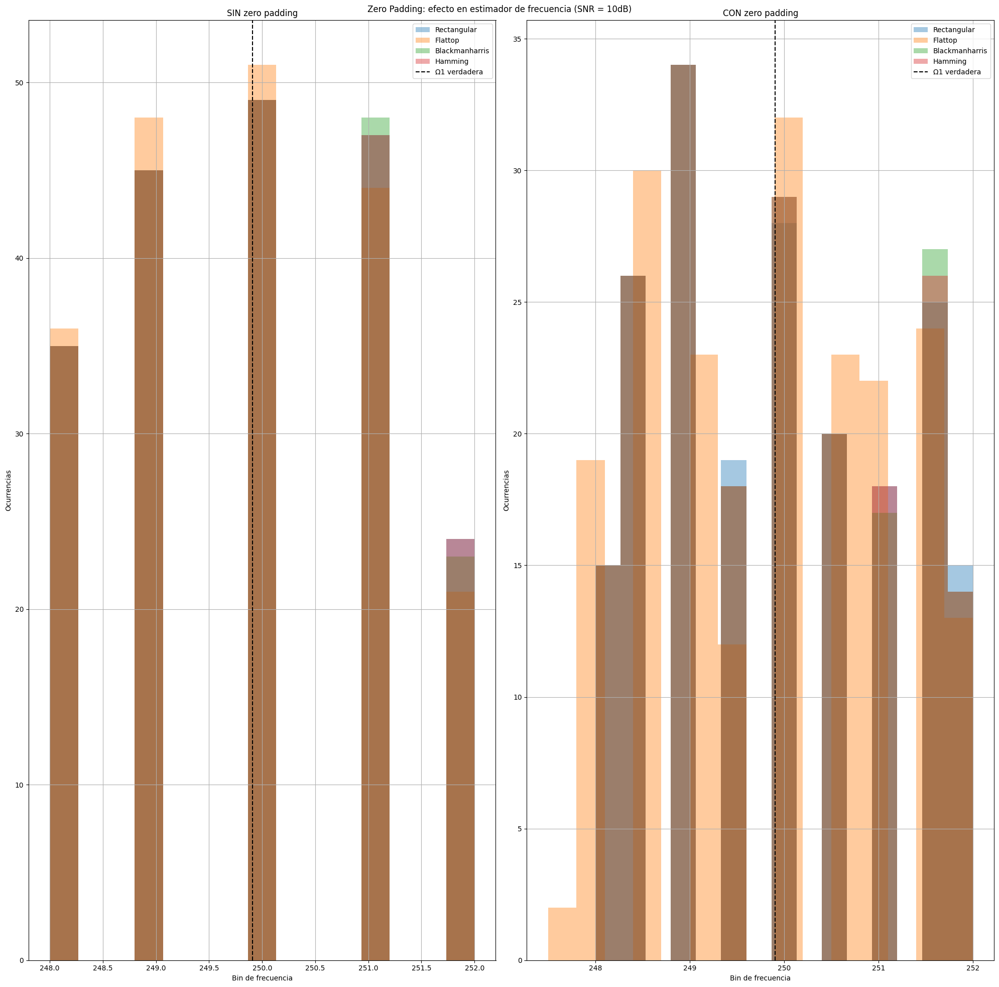

In [28]:
#%% Histograma comparativo ZP vs sin ZP
plt.figure(figsize = (20, 20))
plt.suptitle("Zero Padding: efecto en estimador de frecuencia (SNR = 10dB)")

plt.subplot(1, 2, 1)
plt.title("SIN zero padding")
plt.hist(estimador_f_R10, label = 'Rectangular', alpha = 0.4, bins = 15)
plt.hist(estimador_f_F10,  label = 'Flattop', alpha = 0.4, bins = 15)
plt.hist(estimador_f_B10,  label = 'Blackmanharris', alpha = 0.4, bins = 15)
plt.hist(estimador_f_H10,  label = 'Hamming', alpha = 0.4, bins = 15)
plt.axvline(np.mean(omega1), color = 'k', linestyle = '--', label = 'Ω1 verdadera')
plt.xlabel('Bin de frecuencia')
plt.ylabel('Ocurrencias')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.title("CON zero padding")
plt.hist(estimador_f_zp_R10,      label = 'Rectangular', alpha = 0.4, bins = 15)
plt.hist(estimador_f_zp_F10,     label='Flattop', alpha = 0.4, bins = 15)
plt.hist(estimador_f_zp_B10, label='Blackmanharris', alpha = 0.4, bins = 15)
plt.hist(estimador_f_zp_H10,      label='Hamming',        alpha = 0.4, bins = 15)
plt.axvline(np.mean(omega1), color = 'k', linestyle = '--', label = 'Ω1 verdadera')
plt.xlabel('Bin de frecuencia')
plt.ylabel('Ocurrencias')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

Finalmente, se repitió el mismo análisis para una relación señal a ruido de $SNR = 3dB$.

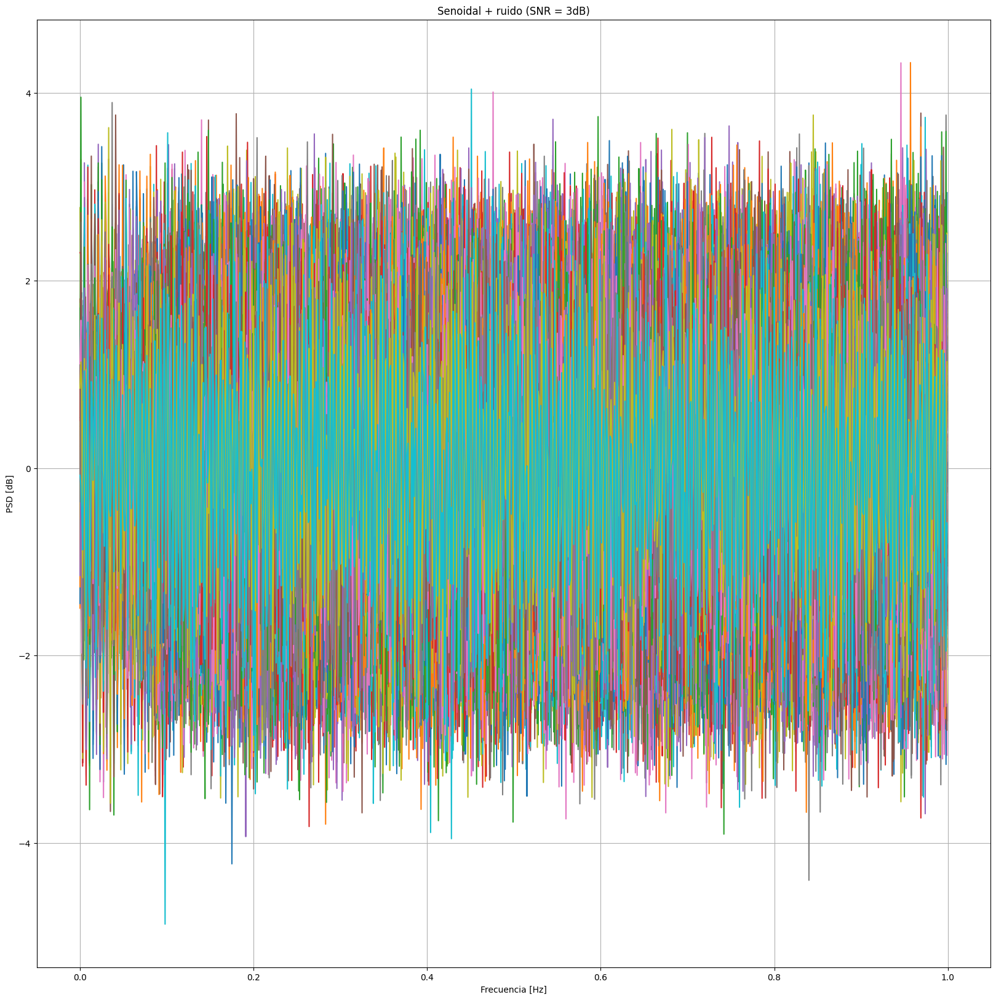

In [29]:
#%% SNR = 3dB
SNR = 3 # en dB
Ps = a0**2 / 2
Pr = Ps / (10**(SNR/10))
desvio = np.sqrt(Pr)

na = np.random.normal(0, desvio, size = (R, N)) # ruido

# Señal
s_mat_3 = a0 * np.sin(2 * np.pi * f * Ts) + na 

# Traspongo la señal para poder graficarla 
señal_t3 = np.transpose(s_mat_3)

plt.figure(figsize = (20, 20))
plt.title("Senoidal + ruido (SNR = 3dB)")
plt.plot(t, señal_t3)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB]') # Es la densidad espectral de potencia 
plt.grid()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

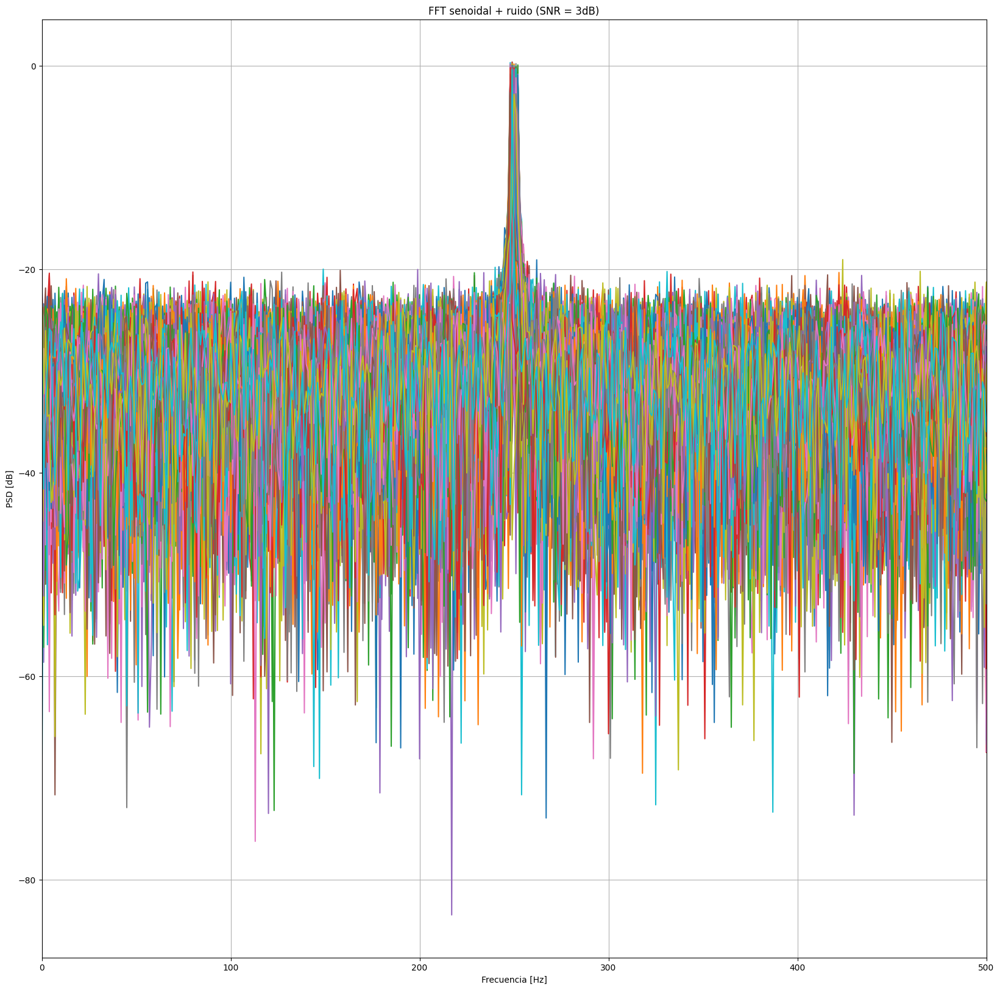

In [30]:
# FFT
eps = 1e-12
S_mat_3 = np.fft.fft(s_mat_3, axis = 1) / N
S_mat_modulo3 = np.abs(S_mat_3)
S_mat_dB3 = 10 * np.log10(2*(S_mat_modulo3)**2 + eps)
S_mat_dB3 = np.transpose(S_mat_dB3)

plt.figure(figsize = (20, 20))
plt.title("FFT senoidal + ruido (SNR = 3dB)")
plt.plot(ff, S_mat_dB3)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB]') # Es la densidad espectral de potencia 
plt.xlim(0, fs/2)
plt.grid()
plt.show

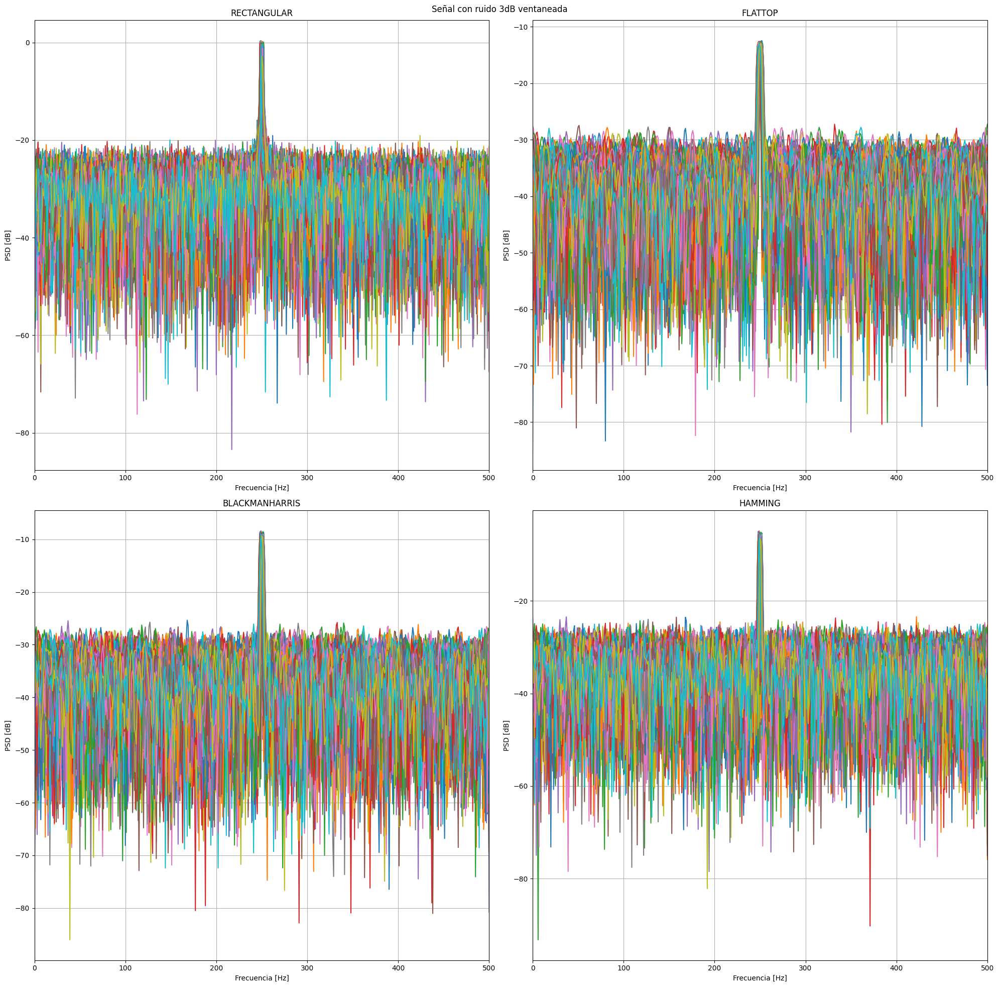

In [31]:
#%% Ventaneo SNR = 3dB
# RECTANGULAR
s_vent_R3 = s_mat_3 * windows.boxcar(N)

S_vent_R3 = np.fft.fft(s_vent_R3, axis=1) / N
S_vent_modulo_R3 = np.abs(S_vent_R3)
S_vent_R3_dB = 10 * np.log10(2*(S_vent_modulo_R3)**2 + eps)
S_vent_R3_dB = np.transpose(S_vent_R3_dB)

# FLATTOP
s_vent_F3 = s_mat_3 * windows.flattop(N)

S_vent_F3 = np.fft.fft(s_vent_F3, axis=1) / N
S_vent_modulo_F3 = np.abs(S_vent_F3)
S_vent_F3_dB = 10 * np.log10(2*(S_vent_modulo_F3)**2 + eps)
S_vent_F3_dB = np.transpose(S_vent_F3_dB)

# BLACKMANHARRIS+
s_vent_B3 = s_mat_3 * windows.blackmanharris(N)

S_vent_B3 = np.fft.fft(s_vent_B3, axis=1) / N
S_vent_modulo_B3 = np.abs(S_vent_B3)
S_vent_B3_dB = 10 * np.log10(2*(S_vent_modulo_B3)**2 + eps)
S_vent_B3_dB = np.transpose(S_vent_B3_dB)

# HAMMING
s_vent_H3 = s_mat_3 * windows.hamming(N)

S_vent_H3 = np.fft.fft(s_vent_H3, axis=1) / N
S_vent_modulo_H3 = np.abs(S_vent_H3)
S_vent_H3_dB = 10 * np.log10(2*(S_vent_modulo_H3)**2 + eps)
S_vent_H3_dB = np.transpose(S_vent_H3_dB)

# Graficos
plt.figure(figsize = (20, 20))
plt.suptitle("Señal con ruido 3dB ventaneada")

plt.subplot(2,2,1)
plt.title("RECTANGULAR")
plt.plot(ff, S_vent_R3_dB)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB]') # Es la densidad espectral de potencia 
plt.xlim(0, fs/2)
plt.grid()

plt.subplot(2,2,2)
plt.title("FLATTOP")
plt.plot(ff, S_vent_F3_dB)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB]') # Es la densidad espectral de potencia 
plt.xlim(0, fs/2)
plt.grid()

plt.subplot(2,2,3)
plt.title("BLACKMANHARRIS")
plt.plot(ff, S_vent_B3_dB)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB]') # Es la densidad espectral de potencia 
plt.xlim(0, fs/2)
plt.grid()

plt.subplot(2,2,4)
plt.title("HAMMING")
plt.plot(ff, S_vent_H3_dB)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD [dB]') # Es la densidad espectral de potencia 
plt.xlim(0, fs/2)
plt.grid()

plt.tight_layout()
plt.show()


In [32]:
#%% Estimador de amplitud SNR = 3dB
estimador_a_R3 = np.abs(S_vent_R3[:, N//4])*2
estimador_a_F3 = np.abs(S_vent_F3[:, N//4])*2
estimador_a_B3 = np.abs(S_vent_B3[:, N//4])*2
estimador_a_H3 = np.abs(S_vent_H3[:, N//4])*2

#%% SESGO Y VARIANZA SNR = 3dB
sesgo_R3 = np.mean(estimador_a_R3) - a0 
sesgo_F3 = np.mean(estimador_a_F3) - a0 
sesgo_B3 = np.mean(estimador_a_B3) - a0 
sesgo_H3 = np.mean(estimador_a_H3) - a0 

varianza_R3 = np.var(estimador_a_R3)
varianza_F3 = np.var(estimador_a_F3)
varianza_B3 = np.var(estimador_a_B3)
varianza_H3 = np.var(estimador_a_H3)

# Tabla de estimación de amplitud
tabla_amp = pd.DataFrame({
    "sesgo": [sesgo_R3, sesgo_F3, sesgo_B3, sesgo_H3],
    "varianza": [varianza_R3, varianza_F3, varianza_B3, varianza_H3]
}, index=["Rectangular", "Flat-top", "Blackman", "Hann"])

titulo = "Estimaion de amplitud (SNR = 3dB)"
print(titulo.center(145))

# Mostrar centradas con HTML
html_amp = tabla_amp.to_html(float_format="%.3f")

display(HTML(f"<div style='display: flex; justify-content: center'>{html_amp}</div>"))


#%% Estimador de la frecuencia SNR = 3dB
estimador_f_R3 = np.argmax(np.abs(S_vent_R3[:, :N//2]), axis=1)
estimador_f_F3 = np.argmax(np.abs(S_vent_F3[:, :N//2]), axis=1)
estimador_f_B3 = np.argmax(np.abs(S_vent_B3[:, :N//2]), axis=1)
estimador_f_H3 = np.argmax(np.abs(S_vent_H3[:, :N//2]), axis=1)

#%% SESGO Y VARIANZA SNR = 3dB
sesgo_frec_R3 = np.mean(estimador_f_R3) - np.mean(omega1)
sesgo_frec_F3 = np.mean(estimador_f_F3) - np.mean(omega1)
sesgo_frec_B3 = np.mean(estimador_f_B3) - np.mean(omega1)
sesgo_frec_H3 = np.mean(estimador_f_H3) - np.mean(omega1)

varianza_frec_R3 = np.var(estimador_f_R3)
varianza_frec_F3 = np.var(estimador_f_F3)
varianza_frec_B3 = np.var(estimador_f_B3)
varianza_frec_H3 = np.var(estimador_f_H3)

# Tabla de estimación de frecuencia
tabla_frec = pd.DataFrame({
    "sesgo": [sesgo_frec_R3, sesgo_frec_F3, sesgo_frec_B3, sesgo_frec_H3],
    "varianza": [varianza_frec_R3, varianza_frec_F3, varianza_frec_B3, varianza_frec_H3]
}, index=["Rectangular", "Flat-top", "Blackman", "Hann"])

titulo = "Estimaion de frecuencia (SNR = 3dB)"
print(titulo.center(145))

# Mostrar centradas con HTML
html_frec = tabla_frec.to_html(float_format="%.3f")

display(HTML(f"<div style='display: flex; justify-content: center'>{html_frec}</div>"))

                                                        Estimaion de amplitud (SNR = 3dB)                                                        


,sesgo,varianza
Rectangular,-0.920,0.212
Flat-top,-1.139,0.001
Blackman,-1.093,0.018
Hann,-1.077,0.072


                                                       Estimaion de frecuencia (SNR = 3dB)                                                       


,sesgo,varianza
Rectangular,-0.003,1.616
Flat-top,0.002,1.632
Blackman,-0.013,1.584
Hann,-0.003,1.616


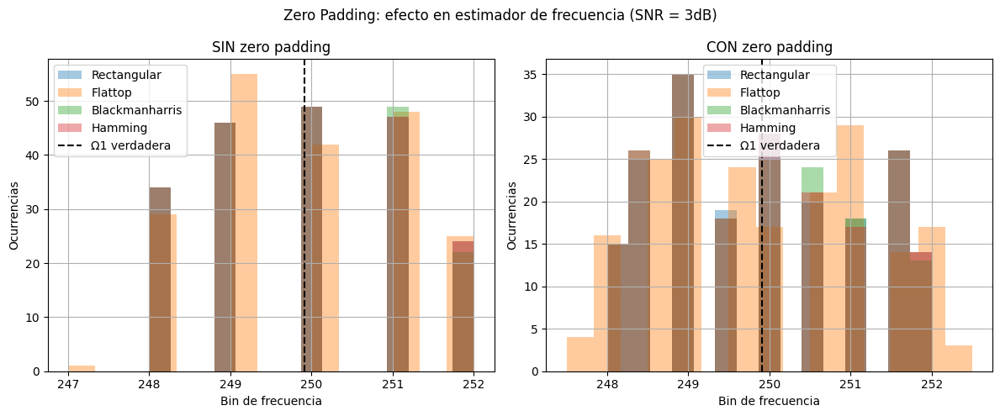

In [33]:
#%% Efecto del zero padding en el estimador de frecuencia (SNR = 3dB)
N_zp = 2 * N  # 2000 puntos

# Rectangular
zp_W_R3 = np.fft.fft(s_vent_R3, n = N_zp, axis = 1)
estimador_f_zp_R3 = np.argmax(np.abs(zp_W_R3[:, :N_zp//2]), axis = 1) / 2
# Dividir por 2 porque los bins ahora son la mitad de anchos

# Flattop
zp_W_F3 = np.fft.fft(s_vent_F3, n = N_zp, axis  =1)
estimador_f_zp_F3 = np.argmax(np.abs(zp_W_F3[:, :N_zp//2]), axis = 1) / 2

# Blackmanharris
zp_W_B3 = np.fft.fft(s_vent_B3, n = N_zp, axis = 1)
estimador_f_zp_B3 = np.argmax(np.abs(zp_W_B3[:, :N_zp//2]), axis = 1) / 2

# Hamming
zp_W_H3 = np.fft.fft(s_vent_H3, n = N_zp, axis = 1)
estimador_f_zp_H3 = np.argmax(np.abs(zp_W_H3[:, :N_zp//2]), axis = 1) / 2

# Sesgo y varianza CON zero padding
sesgo_f_zp_R3 = np.mean(estimador_f_zp_R3) - np.mean(omega1)
sesgo_f_zp_F3 = np.mean(estimador_f_zp_F3) - np.mean(omega1)
sesgo_f_zp_B3 = np.mean(estimador_f_zp_B3) - np.mean(omega1)
sesgo_f_zp_H3 = np.mean(estimador_f_zp_H3) - np.mean(omega1)

var_f_zp_R3 = np.var(estimador_f_zp_R3)
var_f_zp_F3 = np.var(estimador_f_zp_F3)
var_f_zp_B3 = np.var(estimador_f_zp_B3)
var_f_zp_H3 = np.var(estimador_f_zp_H3)

#%% Histograma comparativo ZP vs sin ZP
plt.figure(figsize=(12, 5))
plt.suptitle("Zero Padding: efecto en estimador de frecuencia (SNR = 3dB)")

plt.subplot(1, 2, 1)
plt.title("SIN zero padding")
plt.hist(estimador_f_R3, label = 'Rectangular', alpha = 0.4, bins = 15)
plt.hist(estimador_f_F3,  label = 'Flattop', alpha = 0.4, bins = 15)
plt.hist(estimador_f_B3,  label = 'Blackmanharris', alpha = 0.4, bins = 15)
plt.hist(estimador_f_H3,  label = 'Hamming', alpha = 0.4, bins = 15)
plt.axvline(np.mean(omega1), color = 'k', linestyle = '--', label = 'Ω1 verdadera')
plt.xlabel('Bin de frecuencia')
plt.ylabel('Ocurrencias')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.title("CON zero padding")
plt.hist(estimador_f_zp_R3, label = 'Rectangular', alpha = 0.4, bins = 15)
plt.hist(estimador_f_zp_F3, label='Flattop', alpha = 0.4, bins = 15)
plt.hist(estimador_f_zp_B3, label='Blackmanharris', alpha = 0.4, bins = 15)
plt.hist(estimador_f_zp_H3 , label='Hamming', alpha = 0.4, bins = 15)
plt.axvline(np.mean(omega1), color = 'k', linestyle = '--', label = 'Ω1 verdadera')
plt.xlabel('Bin de frecuencia')
plt.ylabel('Ocurrencias')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# <u> **Conclusiones** <u>

En este trabajo se analizó el comportamiento de distintos estimadores espectrales aplicados a señales sinusoidales contaminadas con ruido blanco gaussiano aditivo (AWGN). A partir de las simulaciones realizadas, se estudió el efecto del nivel de ruido, del tipo de ventana utilizada y del uso de *zero padding* sobre la estimación de amplitud y frecuencia. 

Los valores obtenidos de sesgo y varianza permitieron evaluar la calidad de los estimadores implementados. El sesgo indica qué tan alejado se encuentra el valor promedio estimado respecto del valor real del parámetro, mientras que la varianza mide la dispersión de las estimaciones obtenidas entre distintas realizaciones. Por lo tanto: 

- Un estimador con bajo sesgo produce valores promedio cercanos al verdadero.
- Un estimador con baja varianza genera resultados más estables y consistentes.

A partir de los resultados obtenidos, se verificó que el estimador de amplitud depende fuertemente de la ventana utilizada, ya que el ventaneo modifica la distribución de energía en el espectro. Cuando existe *spectral leakage*, parte de la energía de la componente sinusoidal se dispersa hacia frecuencias vecinas, afectando directamente la amplitud medida en el bin principal de la *FFT*. Por este motivo, distintas ventanas producen diferentes niveles de sesgo y varianza en la estimación de amplitud. 

En particular, la ventana Flattop presentó el menor sesgo en amplitud, ya que está diseñada específicamente para preservar la amplitud de componentes sinusoidales aún cuando existe desintonización respecto de los bins de la *FFT*. Esto pudo observarse también en los histogramas del estimador de amplitud, donde las distribuciones asociadas a esta ventana aparecieron más concentradas alrededor del valor real. 

Por otro lado, la ventana Rectangular mostró mejor resolución espectral debido a su lóbulo principal angosto, aunque presentó mayor *spectral leakage* producto de sus lóbulos secundarios elevados. Esto provocó una mayor dispersión espectral y estimaciones más sensibles a pequeñas variaciones de frecuencia. 

Las ventanas Hamming y Blackman-Harris mostraron un comportamiento intermedio. Ambas redujeron considerablemente el leakage respecto de la Rectangular, produciendo espectros más suaves y estimaciones más robustas frente al ruido. Sin embargo, el ensanchamiento del lóbulo principal redujo parcialmente la capacidad de distinguir frecuencias cercanas. 

En consecuencia, la elección de la ventana va a depender del objetivo del análisis: 

- Si se busca máxima resolución en frecuencia, conviene utilizar la ventana Rectangular.
- Si se desea minimizar el error en amplitud, la ventana Flattop resulta más adecuada.
- Si se necesita un compromiso entre resolución y reducción de leakage, las ventanas de Hamming o la de Blackman-Harris representan mejores alternativas.

Respecto al estimador de frecuencia, se observó que su desempeño depende principalmente de la localización del máximo espectral. En este caso, las ventanas con menor leakage tendieron a producir histogramas más concentrados alrededor de la frecuencia real, reduciendo errores producidos por la dispersión espectral.

La comparación entre los casos $SNR=10dB$ y $SNR=3dB$ permitió observar claramente el efecto del ruido sobre los estimadores. Para $10dB$, los histogramas presentaron distribuciones más angostas y concentradas, indicando menor varianza y mayor precisión en las estimaciones. En cambio, para $3dB$, el aumento de potencia de ruido produjo una mayor dispersión tanto en el estimador de amplitud como en el de frecuencia.

Este comportamiento se reflejó especialmente en los histogramas del estimador de frecuencia, donde el ruido dificultó la identificación precisa del máximo espectral. Como consecuencia, aumentó la variabilidad de las estimaciones y se incrementó la varianza del estimador frecuencial.

Además, se comprobó que el uso de *zero padding* mejora significativamente la estimación de frecuencia. Aunque esta técnica no incrementa la resolución espectral real ni añade información nueva a la señal, sí genera una interpolación más densa del espectro calculado mediante la *FFT*. Esto permite localizar el máximo espectral con mayor precisión y reducir la varianza del estimador de frecuencia. 

En consecuencia, el *zero padding* proporciona una "resolución espectral aparente" más fina, que resulta especialmente útil para tareas de estimación frecuencial aun cuando la resolución física edl sistema permanece inalterada. 

Finalmente, al trabajar con múltiples realizaciones de ruido blanco gaussiano de media nula, el promediado estadístico permitió reducir parcialmente el efecto aleatorio del ruido sobre las estimaciones. Esto se relaciona con el comportamiento ergódico y estacionario del proceso de ruido considerado, donde los promedios muestrales tienden a aproximarse a los valores esperados teóricos.

En conclusión, los resultados obtenidos fueron consistentes con la teoría de procesamiento digital de señales y análisis espectral, verificando experimentalmente el compromiso existente entre resolución espectral, leakage, precisión de amplitud y robustez frente al ruido.